Loading features from: ../data/processed/delhi_engineered_features.csv
=== 2024 Validation Performance across Feature Regimes ===


,Feature_Set,Model,MAE,RMSE,R2
0,A_Pollution_Only,Random_Forest,23.638458,36.851985,0.748940
1,C_Combined,Random_Forest,23.823812,36.154982,0.758348
2,C_Combined,Gradient_Boosting,24.775007,38.236062,0.729728
3,A_Pollution_Only,Ridge,24.847520,37.558214,0.739226
4,C_Combined,Ridge,24.916245,37.172308,0.744557
5,A_Pollution_Only,Gradient_Boosting,25.631676,40.553553,0.695973
6,B_Weather_Only,Gradient_Boosting,34.268721,49.479197,0.547415
7,B_Weather_Only,Random_Forest,35.061558,49.478491,0.547428
8,B_Weather_Only,Ridge,44.247241,55.897649,0.422380



=== FINAL 2025 TEST BENCHMARK ===


,Model,MAE,RMSE,R2
0,"ARIMA(2, 0, 2)",21.767807,32.802882,0.830426
1,Random_Forest,22.204066,32.782095,0.830641
2,Ridge,22.386264,32.520557,0.833332
3,Gradient_Boosting,22.817040,33.163089,0.826681
4,Baseline (Persistence),23.228300,34.901979,0.808504
5,Baseline (7-Day Mean),29.586635,44.951592,0.682639


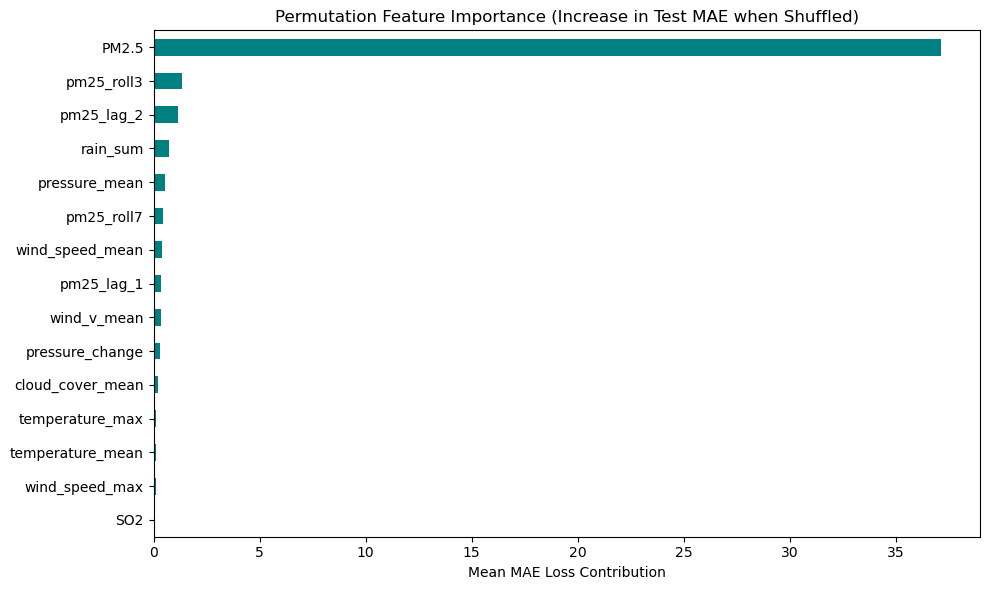


=== Seasonal Forecast Breakdown (2025 Test) ===


,season,MAE,Observed_Count,Avg_Actual_PM25
0,Monsoon,9.341841,113,39.653009
1,Post-Monsoon,31.536538,61,173.912459
2,Summer,17.205020,92,69.048261
3,Winter,39.562749,90,163.100667


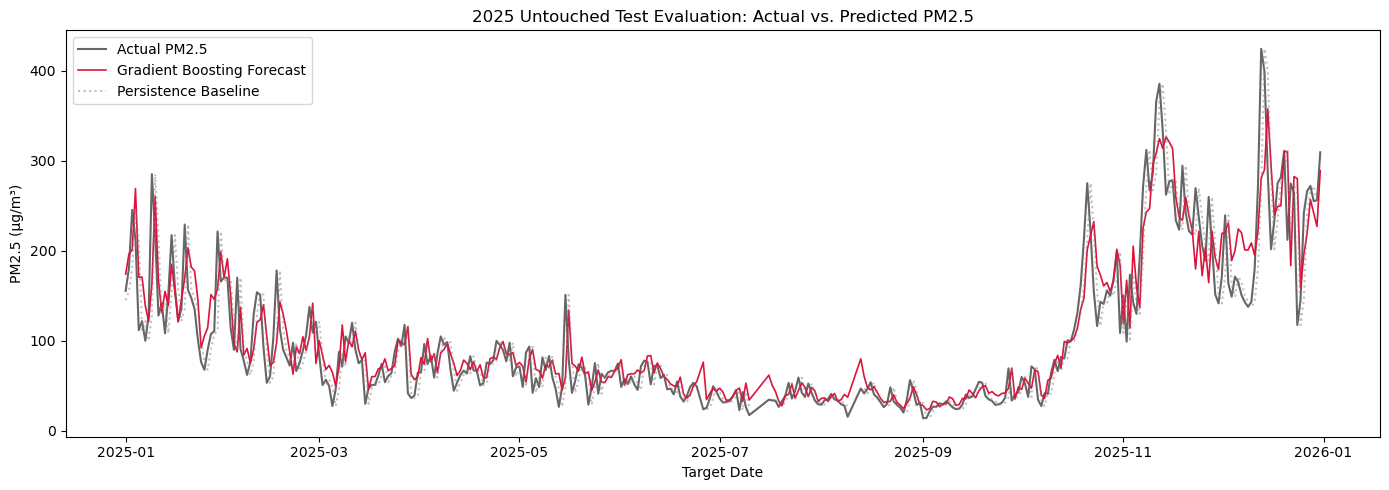


Successfully serialized artifacts into '../results/models':
  - Pipeline:       ../results/models\final_model.joblib
  - Feature Schema: ../results/models\feature_columns.joblib


In [2]:
# %% [markdown]
# # Notebook 5: Machine Learning Forecasting, Benchmarking & Model Export

# %%
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Ensure all target directories exist
plot_dir = "../plots" if os.path.exists("../plots") or os.path.exists("..") else "plots"
table_dir = "../results/tables" if os.path.exists("../results") or os.path.exists("..") else "results/tables"
model_dir = "../results/models" if os.path.exists("../results") or os.path.exists("..") else "results/models"

os.makedirs(plot_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)
os.makedirs(model_dir, exist_ok=True)

# %%
# 1. Load engineered features
candidates = [
    "../data/processed/delhi_engineered_features.csv",
    "data/processed/delhi_engineered_features.csv",
    "delhi_engineered_features.csv"
]
feat_path = next(p for p in candidates if os.path.exists(p))
print(f"Loading features from: {feat_path}")

data = pd.read_csv(feat_path)
data["Date"] = pd.to_datetime(data["Date"])
data["target_date"] = pd.to_datetime(data["target_date"])

# %%
# 2. Define Feature Regimes
feature_sets = {
    "A_Pollution_Only": [
        "PM2.5", "pm25_lag_1", "pm25_lag_2", "pm25_lag_3", "pm25_lag_7",
        "pm25_roll3", "pm25_roll7", "PM10", "NO2", "SO2",
        "month_sin", "month_cos", "is_weekend"
    ],
    "B_Weather_Only": [
        "temperature_mean", "temperature_min", "temperature_max", "temp_range",
        "humidity_mean", "dew_point_mean", "rain_sum", "pressure_mean",
        "pressure_change", "cloud_cover_mean", "wind_speed_mean", "wind_speed_max",
        "wind_u_mean", "wind_v_mean", "month_sin", "month_cos", "is_weekend"
    ],
    "C_Combined": [
        "PM2.5", "pm25_lag_1", "pm25_lag_2", "pm25_lag_3", "pm25_lag_7",
        "pm25_roll3", "pm25_roll7", "PM10", "NO2", "SO2",
        "temperature_mean", "temperature_min", "temperature_max", "temp_range",
        "humidity_mean", "dew_point_mean", "rain_sum", "pressure_mean",
        "pressure_change", "cloud_cover_mean", "wind_speed_mean", "wind_speed_max",
        "wind_u_mean", "wind_v_mean", "month_sin", "month_cos", "is_weekend"
    ]
}

# %%
# 3. Chronological Splits Based on target_date
train_mask = data["target_date"] < "2024-01-01"
val_mask = (data["target_date"] >= "2024-01-01") & (data["target_date"] < "2025-01-01")
test_mask = (data["target_date"] >= "2025-01-01") & (data["target_date"] < "2026-01-01")

y_train = data.loc[train_mask, "target_next_day"]
y_val = data.loc[val_mask, "target_next_day"]
y_test = data.loc[test_mask, "target_next_day"]

test_meta = data.loc[test_mask, ["target_date", "PM2.5", "target_next_day", "season"]].copy()

def compute_metrics(actual, pred):
    valid_idx = ~np.isnan(actual) & ~np.isnan(pred)
    a, p = actual[valid_idx], pred[valid_idx]
    return {
        "MAE": mean_absolute_error(a, p),
        "RMSE": np.sqrt(mean_squared_error(a, p)),
        "R2": r2_score(a, p)
    }

# %%
# 4. Baselines Evaluation
# Persistence: y_hat_{t+1} = y_t
persistence_val_pred = data.loc[val_mask, "PM2.5"].values
persistence_test_pred = data.loc[test_mask, "PM2.5"].values

# 7-day average: y_hat_{t+1} = roll7
mean7_val_pred = data.loc[val_mask, "pm25_roll7"].values
mean7_test_pred = data.loc[test_mask, "pm25_roll7"].values

# %%
# 5. Define ML Model Pipelines & Evaluate on 2024 Validation Set
pipelines = {
    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random_Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_depth=12, random_state=42, n_jobs=-1))
    ]),
    "Gradient_Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(learning_rate=0.04, max_iter=250, max_leaf_nodes=25, random_state=42))
    ])
}

val_records = []
for f_name, f_cols in feature_sets.items():
    X_tr = data.loc[train_mask, f_cols]
    X_v = data.loc[val_mask, f_cols]
    
    for m_name, pipe in pipelines.items():
        pipe.fit(X_tr, y_train)
        preds = pipe.predict(X_v)
        metrics = compute_metrics(y_val.values, preds)
        val_records.append({"Feature_Set": f_name, "Model": m_name, **metrics})

val_results_df = pd.DataFrame(val_records).sort_values("MAE").reset_index(drop=True)
print("=== 2024 Validation Performance across Feature Regimes ===")
display(val_results_df)

chosen_features = feature_sets["C_Combined"]

# %%
# 6. Final Evaluation on Untouched 2025 Test Set (Trained on 2020-2024 history)
train_val_mask = train_mask | val_mask
X_train_val = data.loc[train_val_mask, chosen_features]
y_train_val = data.loc[train_val_mask, "target_next_day"]
X_test = data.loc[test_mask, chosen_features]

test_records = [
    {"Model": "Baseline (Persistence)", **compute_metrics(y_test.values, persistence_test_pred)},
    {"Model": "Baseline (7-Day Mean)", **compute_metrics(y_test.values, mean7_test_pred)}
]

final_test_preds = {}
for m_name, pipe in pipelines.items():
    pipe.fit(X_train_val, y_train_val)
    preds = pipe.predict(X_test)
    final_test_preds[m_name] = preds
    test_records.append({"Model": m_name, **compute_metrics(y_test.values, preds)})

# Load ARIMA results from Notebook 3 if available
arima_file = os.path.join(table_dir, "arima_test_metrics.csv")
if os.path.exists(arima_file):
    arima_res = pd.read_csv(arima_file).to_dict("records")[0]
    test_records.append(arima_res)

final_benchmark = pd.DataFrame(test_records).sort_values("MAE").reset_index(drop=True)
print("\n=== FINAL 2025 TEST BENCHMARK ===")
display(final_benchmark)
final_benchmark.to_csv(os.path.join(table_dir, "final_model_benchmark_2025.csv"), index=False)

# %%
# 7. Permutation Feature Importance
best_pipeline = pipelines["Gradient_Boosting"]
perm_res = permutation_importance(best_pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring="neg_mean_absolute_error")
feat_imp = pd.Series(perm_res.importances_mean, index=chosen_features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feat_imp.head(15).plot(kind="barh", color="teal")
plt.title("Permutation Feature Importance (Increase in Test MAE when Shuffled)")
plt.xlabel("Mean MAE Loss Contribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "08_permutation_importance.png"), dpi=300)
plt.show()

# %%
# 8. Seasonal Performance Breakdown
test_meta["GB_Pred"] = final_test_preds["Gradient_Boosting"]
test_meta["Error_MAE"] = np.abs(test_meta["target_next_day"] - test_meta["GB_Pred"])

seasonal_perf = test_meta.groupby("season").agg(
    MAE=("Error_MAE", "mean"),
    Observed_Count=("target_next_day", "count"),
    Avg_Actual_PM25=("target_next_day", "mean")
).reset_index()

print("\n=== Seasonal Forecast Breakdown (2025 Test) ===")
display(seasonal_perf)
seasonal_perf.to_csv(os.path.join(table_dir, "seasonal_performance_breakdown.csv"), index=False)

# %%
# 9. Final Forecast Visualization
plt.figure(figsize=(14, 5))
plt.plot(test_meta["target_date"], test_meta["target_next_day"], label="Actual PM2.5", color="black", alpha=0.6)
plt.plot(test_meta["target_date"], test_meta["GB_Pred"], label="Gradient Boosting Forecast", color="crimson", linewidth=1.2)
plt.plot(test_meta["target_date"], persistence_test_pred, label="Persistence Baseline", color="gray", linestyle=":", alpha=0.5)
plt.title("2025 Untouched Test Evaluation: Actual vs. Predicted PM2.5")
plt.xlabel("Target Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "09_test_actual_vs_predicted.png"), dpi=300)
plt.show()

# %%
# 10. Freeze and Export Production Model Artifacts
champion_model_name = "Gradient_Boosting"
champion_pipeline = pipelines[champion_model_name]

# Retrain on full historical context (2020-2024) to lock in production weights
champion_pipeline.fit(X_train_val, y_train_val)

model_export_path = os.path.join(model_dir, "final_model.joblib")
features_export_path = os.path.join(model_dir, "feature_columns.joblib")

joblib.dump(champion_pipeline, model_export_path)
joblib.dump(chosen_features, features_export_path)

print(f"\nSuccessfully serialized artifacts into '{model_dir}':")
print(f"  - Pipeline:       {model_export_path}")
print(f"  - Feature Schema: {features_export_path}")